#**Pengolahan Dataset 1-train_FD001.txt**
Menghubungkan pada google drive, mendefinisikan kolom (26 kolom), melakukan load dataset, dan memeriksa/menampilkan 5 baris pertama menggunakan df_train.head()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

file_path = '/content/drive/MyDrive/Praktikum MLN/Dataset ML/train_FD001.txt'

kolom = ['unit_id', 'cycle', 'setting_1', 'setting_2', 'setting_3'] + \
        [f'sensor_{i}' for i in range(1, 22)]

# 3. Load dataset
df_train = pd.read_csv(file_path, sep=r'\s+', header=None, names=kolom)

# 4. Tampilkan 5 baris pertama
df_train.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


melakukan pemeriksaan statistik deskriptif pada dataset, mencari kolom yang nilainya tidak pernah berubah, menghapus kolom yang nilainya tidak pernah berubah dan memeriksa sisa jumlah kolom saat ini

In [ ]:
deskripsi = df_train.describe()

kolom_konstan = deskripsi.columns[deskripsi.loc['std'] == 0].tolist()
print("Kolom yang konstan dan akan dibuang:", kolom_konstan)

df_train = df_train.drop(columns=kolom_konstan)

print("Bentuk dataset sekarang (baris, kolom):", df_train.shape)

Kolom yang konstan dan akan dibuang: ['setting_3', 'sensor_18', 'sensor_19']
Bentuk dataset sekarang (baris, kolom): (20631, 23)


* Prinsip Zero Variance (Tidak Ada Variansi): Model machine learning belajar dengan cara mencari korelasi antara perubahan nilai sensor dengan perubahan target (RUL). Jika sebuah sensor terus-menerus menunjukkan angka "100" dari saat mesin sehat hingga mesin meledak, sensor tersebut tidak membawa sinyal atau informasi apa pun tentang kapan mesin akan rusak.

* Menghindari Curse of Dimensionality: Mempertahankan kolom yang diam (statis) hanya akan menambah beban komputasi secara sia-sia. Dalam algoritma seperti Neural Network atau Random Forest, fitur statis ini bisa menjadi noise yang justru mengganggu model saat mencari bobot (weights) yang optimal.

* Kepastian 100%: Untuk dataset FD001, ya, kita bisa memastikan data itu tidak dibutuhkan. Namun berikan catatan penting ke temanmu: Pada dataset FD002 (yang punya 6 kondisi cuaca/ketinggian), sensor yang tadinya diam di FD001 mungkin akan mulai bergerak merespons perubahan ketinggian pesawat. Jadi, pembuangan fitur statis harus dievaluasi ulang di setiap sub-dataset.

selanjutnya melakukan pelabelan:
1. mencari suklus maksimal (kapan mesin mengalami kerusakan) untuk setiap unit_id
2. menggabungkan informasi siklus maksimal pada dataframe utama
3. menghitung RUL (siklus maksimal-siklus saat ini)
4. menghapus kembali kolom siklus maksimal setelah menemukan RUL
5. melihat hasil RUL pada 10 data pertama

In [ ]:
max_cycle = df_train.groupby('unit_id')['cycle'].max().reset_index()
max_cycle.columns = ['unit_id', 'max_cycle']

df_train = df_train.merge(max_cycle, on='unit_id', how='left')

df_train['RUL'] = df_train['max_cycle'] - df_train['cycle']

df_train = df_train.drop(columns=['max_cycle'])

print(df_train[['unit_id', 'cycle', 'RUL']].head(10))

   unit_id  cycle  RUL
0        1      1  191
1        1      2  190
2        1      3  189
3        1      4  188
4        1      5  187
5        1      6  186
6        1      7  185
7        1      8  184
8        1      9  183
9        1     10  182


#Analisis Dataset 1- train_FD001.txt
melihat tren sensor (degradasi mesin), dengan memeriksa salah satu mesin dan melihat pergerakan sensornya dari mesin sehat sampai rusak (contoh yang diperiksa pergerakan sensor_2)

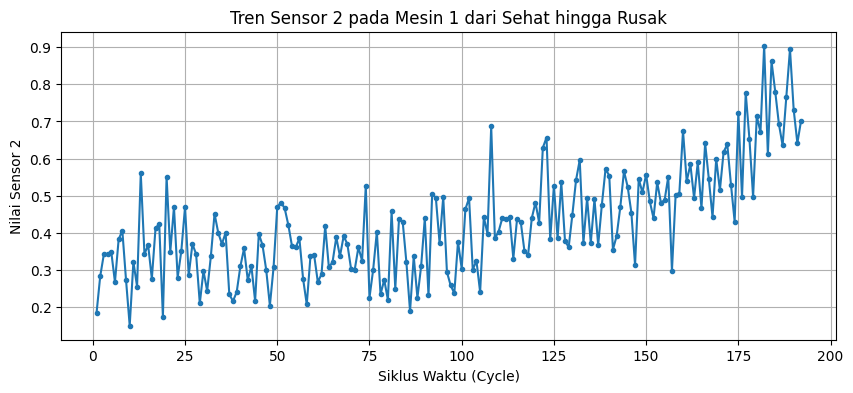

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_mesin1 = df_train[df_train['unit_id'] == 1]

plt.figure(figsize=(10, 4))
plt.plot(df_mesin1['cycle'], df_mesin1['sensor_2'], marker='.')
plt.title('Tren Sensor 2 pada Mesin 1 dari Sehat hingga Rusak')
plt.xlabel('Siklus Waktu (Cycle)')
plt.ylabel('Nilai Sensor 2')
plt.grid(True)
plt.show()

* Grafik garis "Tren Sensor 2 pada Mesin 1" memperlihatkan bahwa pada awal siklus
saat mesin masih sehat, pembacaan nilai sensor berfluktuasi di kisaran angka yang lebih rendah.  
* Seiring bertambahnya siklus pengoperasian mendekati angka 200 (mendekati titik kerusakan total), nilai sensor menunjukkan tren peningkatan yang tajam dan signifikan hingga mencapai skala di atas 0.8.   
* Pola ini membuktikan bahwa sensor_2 secara efektif merekam jejak keausan mesin dari waktu ke waktu, yang sangat penting untuk melatih algoritma prediktif.

##Trajektori Degradasi (Degradation Trajectory).
melihat pergerakan "status kesehatan mesin secara keseluruhan" dari waktu ke waktu.

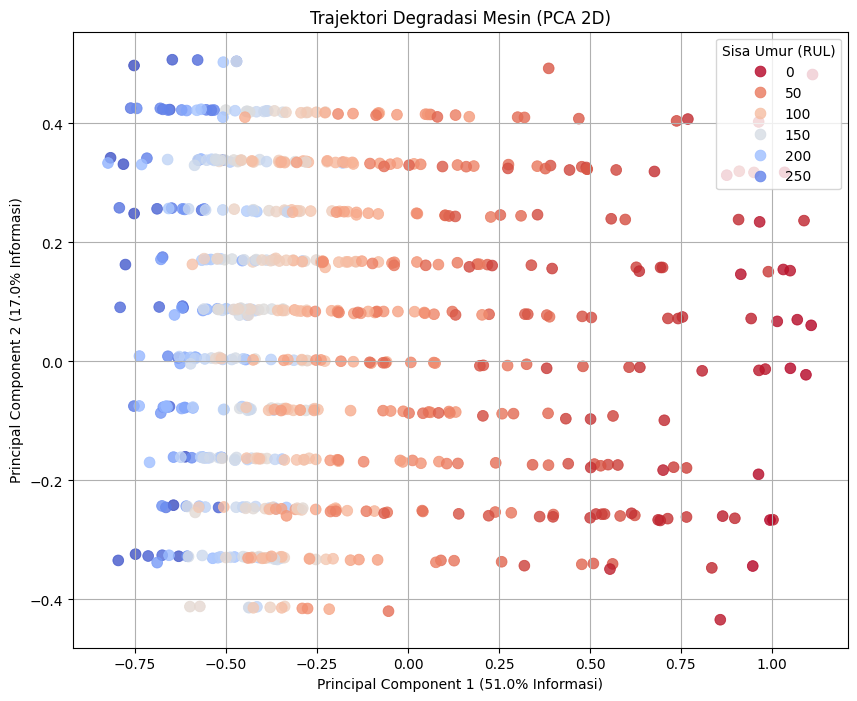

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ambil hanya kolom sensor yang sudah di-scale sebelumnya
fitur_sensor = df_train[kolom_fitur]

# 2. Lakukan PCA untuk memadatkan belasan sensor menjadi 2 komponen saja
pca = PCA(n_components=2)
pca_result = pca.fit_transform(fitur_sensor)

# 3. Masukkan hasil PCA ke dalam dataframe baru agar mudah di-plot
df_pca = pd.DataFrame(pca_result, columns=['PC1', 'PC2'])
df_pca['RUL'] = df_train['RUL']
df_pca['unit_id'] = df_train['unit_id']

# 4. Kita buat visualisasi pergerakan degradasi untuk 3 mesin pertama saja
# (Jika semua mesin di-plot sekaligus, grafiknya akan terlalu penuh dan bertumpuk)
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='RUL', # Warna titik didasarkan pada sisa umur mesin
    palette='coolwarm_r', # Merah: RUL tipis (rusak), Biru: RUL panjang (sehat)
    data=df_pca[df_pca['unit_id'].isin([1, 2, 3])],
    s=60, alpha=0.8, edgecolor=None
)

plt.title('Trajektori Degradasi Mesin (PCA 2D)')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Informasi)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Informasi)')
plt.legend(title='Sisa Umur (RUL)')
plt.grid(True)
plt.show()

* Sumbu X (Principal Component 1): Sumbu ini paling krusial karena berhasil menangkap 51% variansi atau pola informasi dari gabungan seluruh sensor.
* Pergeseran Degradasi: Terlihat pola migrasi yang sangat jelas dari kiri ke kanan. Titik-titik berwarna biru mewakili mesin yang masih sehat dengan Sisa Umur (RUL) tinggi (sekitar 200-250 siklus) yang menumpuk di sisi kiri grafik. Seiring berjalannya waktu pengoperasian, titik tersebut bergeser ke kanan dan perlahan berubah warna menjadi merah tua, yang menandakan RUL telah menyentuh angka 0 (mesin rusak).   
* Kesimpulan Visual: Pola linier mendatar ini mengonfirmasi kepada tim modeling bahwa meskipun data mesin memiliki banyak dimensi sensor, ada sebuah tren keausan universal yang sangat kuat dan sangat mudah diprediksi oleh algoritma machine learning.

selanjutnya melihat korelasi sensor dengan RUL yang sudah dibuat sebelumnya dengan menghitung korelasi antar kolom terhadap RUL dan melihat hasilnya pada heatmap korelasi.

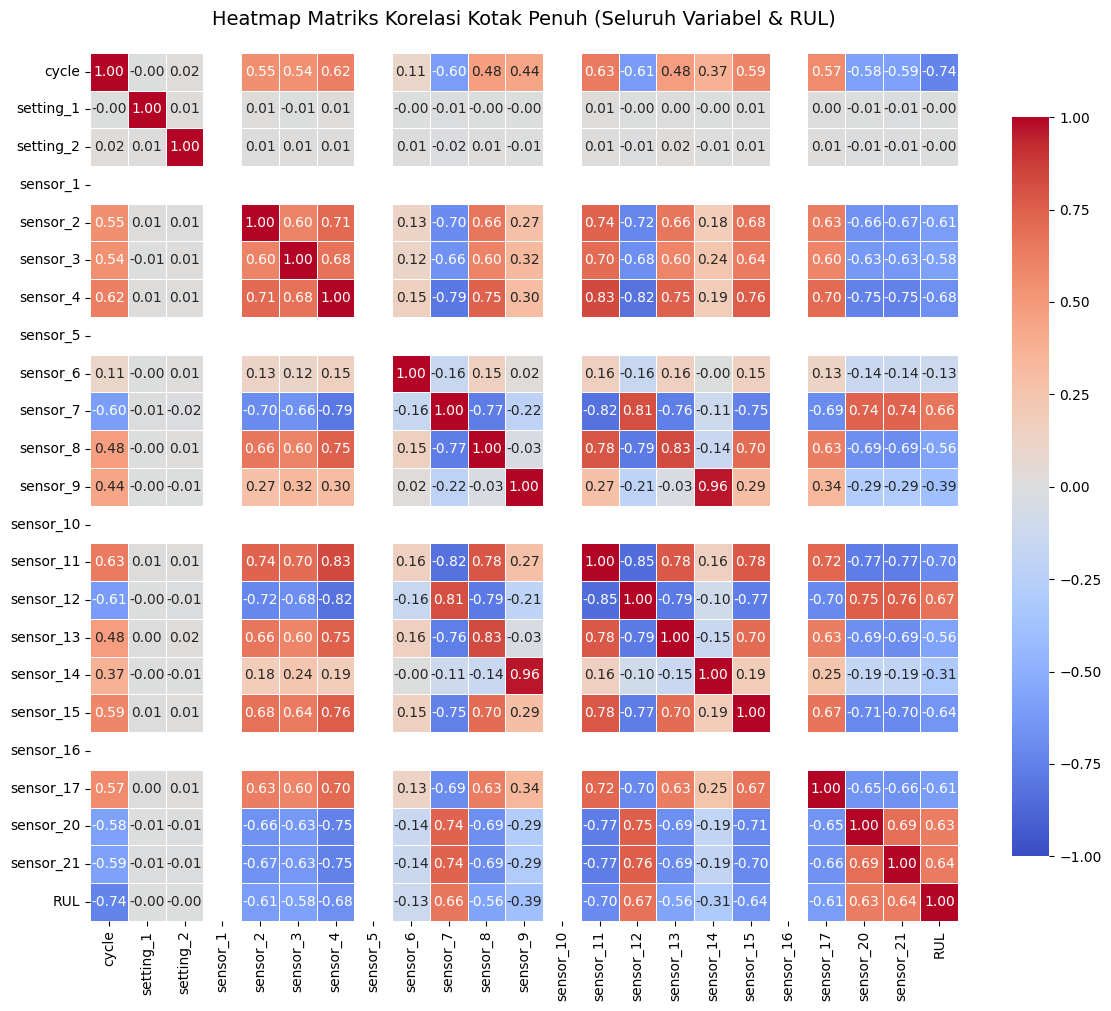

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pilih kolom yang akan dihitung korelasinya (semua fitur + RUL, tanpa unit_id)
kolom_evaluasi = [col for col in df_train.columns if col != 'unit_id']

# 2. Hitung matriks korelasi penuh
matriks_korelasi = df_train[kolom_evaluasi].corr()

# 3. Buat Heatmap Matriks Kotak
plt.figure(figsize=(14, 12))
sns.heatmap(
    matriks_korelasi,
    annot=True,           # Menampilkan angka nilai korelasi di dalam kotak
    fmt='.2f',            # Pembulatan 2 angka di belakang koma
    cmap='coolwarm',      # Warna: Merah = Korelasi Positif, Biru = Korelasi Negatif
    vmin=-1, vmax=1,
    square=True,          # PENTING: Memaksa setiap petak berbentuk KOTAK sempurna
    linewidths=0.5,       # Garis pemisah antar kotak
    cbar_kws={"shrink": 0.8}
)

plt.title('Heatmap Matriks Korelasi Kotak Penuh (Seluruh Variabel & RUL)', fontsize=14, pad=20)
plt.show()

* Heatmap tersebut membedah seberapa besar pengaruh setiap sensor terhadap sisa umur mesin (RUL).   
* Fitur dengan korelasi negatif terkuat adalah cycle (-0.74), sensor_11 (-0.70), sensor_4 (-0.68), dan sensor_2 (-0.61). Nilai negatif berarti ketika RUL semakin kecil (mesin hampir rusak), nilai pada sensor-sensor tersebut akan semakin tinggi. Hal ini sejalan dengan bukti di grafik garis sensor_2 sebelumnya.   
* Sebaliknya, sensor dengan korelasi positif terkuat adalah sensor_12 (0.67), sensor_7 (0.66), dan sensor_21 (0.64). Nilainya akan ikut menurun bersamaan dengan menipisnya RUL mesin.   
* Fitur operasional seperti setting_1 (-0.0032) dan setting_2 (-0.0019), serta unit_id (0.079) memiliki nilai korelasi yang sangat mendekati angka nol. Ini menunjukkan bahwa variabel tersebut nyaris tidak memiliki hubungan prediktif terhadap target RUL pada kondisi pengujian dasar ini.

##Scatterplot untuk Sensor Berkorelasi Tinggi

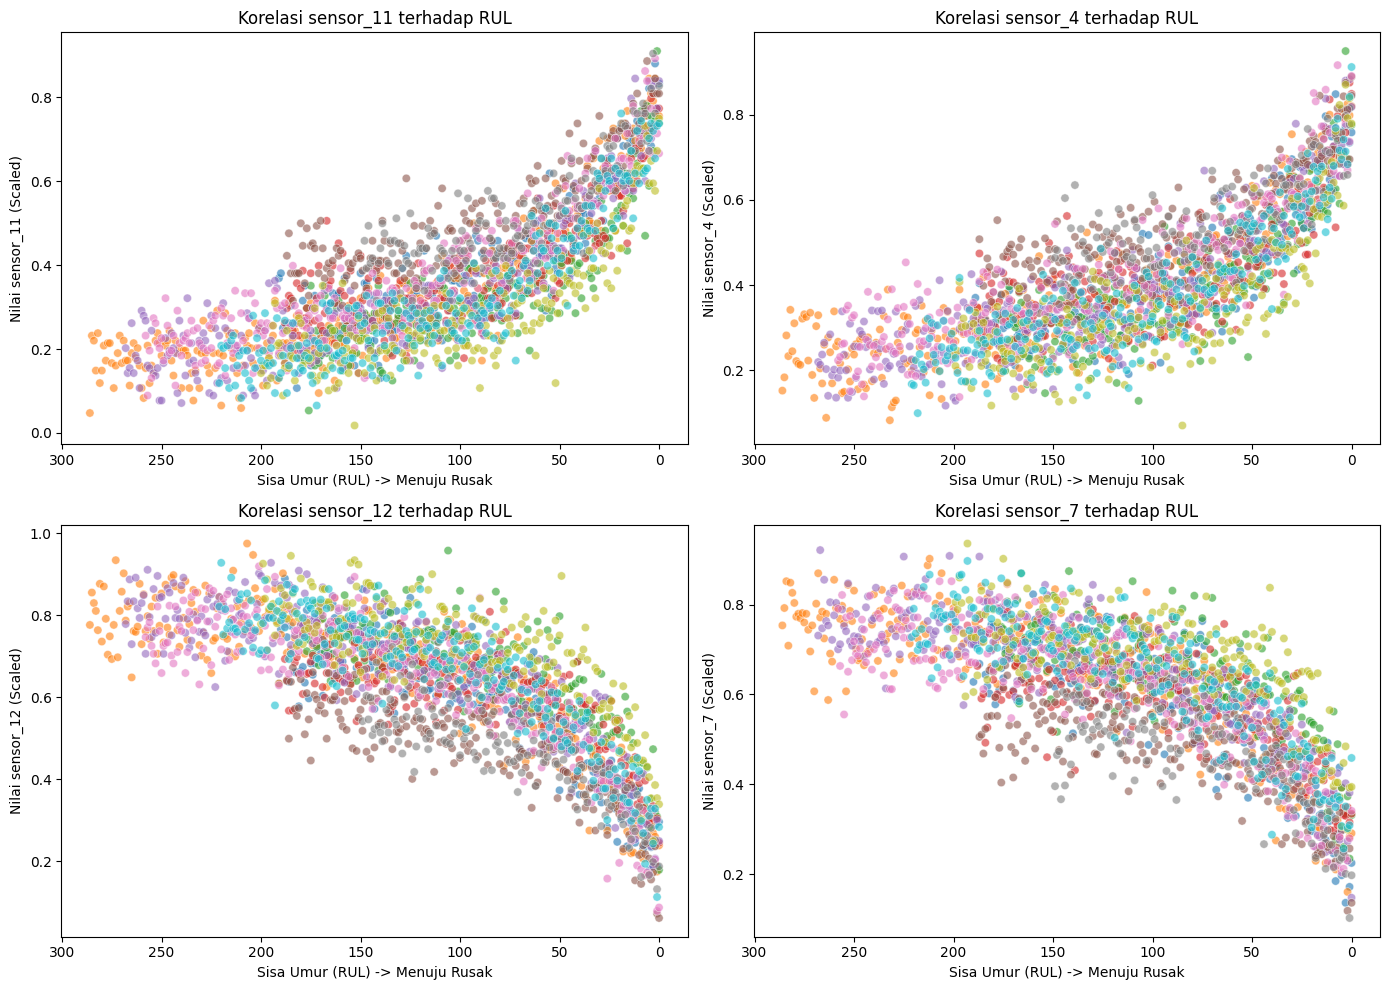

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pilih beberapa sensor dengan korelasi tertinggi (baik positif maupun negatif)
# Berdasarkan heatmap sebelumnya: sensor_11, sensor_4, sensor_12, sensor_7
sensor_penting = ['sensor_11', 'sensor_4', 'sensor_12', 'sensor_7']

# 2. Siapkan kanvas grafik dengan 2 baris dan 2 kolom
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

# 3. Looping untuk membuat scatterplot setiap sensor terhadap RUL
# Kita ambil sampel 10 mesin pertama saja agar titik tidak terlalu menumpuk
df_sample = df_train[df_train['unit_id'] <= 10]

for i, sensor in enumerate(sensor_penting):
    sns.scatterplot(
        data=df_sample,
        x='RUL',
        y=sensor,
        hue='unit_id',
        palette='tab10',
        ax=axes[i],
        alpha=0.6,
        legend=False
    )
    # Membalik sumbu X agar sejalan dengan waktu (RUL besar di kiri, RUL 0 di kanan)
    axes[i].invert_xaxis()
    axes[i].set_title(f'Korelasi {sensor} terhadap RUL')
    axes[i].set_xlabel('Sisa Umur (RUL) -> Menuju Rusak')
    axes[i].set_ylabel(f'Nilai {sensor} (Scaled)')

plt.tight_layout()
plt.show()

* Pola Tren Naik (Korelasi Negatif): Pada grafik sensor_11 dan sensor_4 (baris atas), kamu bisa melihat bahwa saat mesin semakin mendekati kerusakan (RUL menuju 0 di sebelah kanan), nilai sensornya secara perlahan merambat naik dan memuncak secara eksponensial di akhir siklus.   
* Pola Tren Turun (Korelasi Positif): Sebaliknya, pada grafik sensor_12 dan sensor_7 (baris bawah), nilai pembacaan sensor pada awalnya stabil di angka yang tinggi saat mesin sehat, namun konsisten menurun tajam seiring habisnya sisa umur mesin.   
* Konsistensi Antar Mesin: Titik-titik dengan warna yang berbeda mewakili sampel mesin (unit_id) yang berbeda-beda. Terlihat bahwa terlepas dari mesin mana pun yang sedang diuji, semuanya membentuk pola lengkungan lintasan degradasi yang sangat seragam.   

Kesimpulan untuk presentasimu:
Visualisasi ini adalah bukti kuat yang mengonfirmasi angka-angka pada heatmap sebelumnya. Kamu bisa menyampaikan kepada teman kelompokmu bahwa keempat sensor ini memiliki sinyal prediktif yang sangat konsisten, sehingga model machine learning regresi yang akan dibuat pasti dapat mempelajari pola kerusakan ini dengan sangat baik.

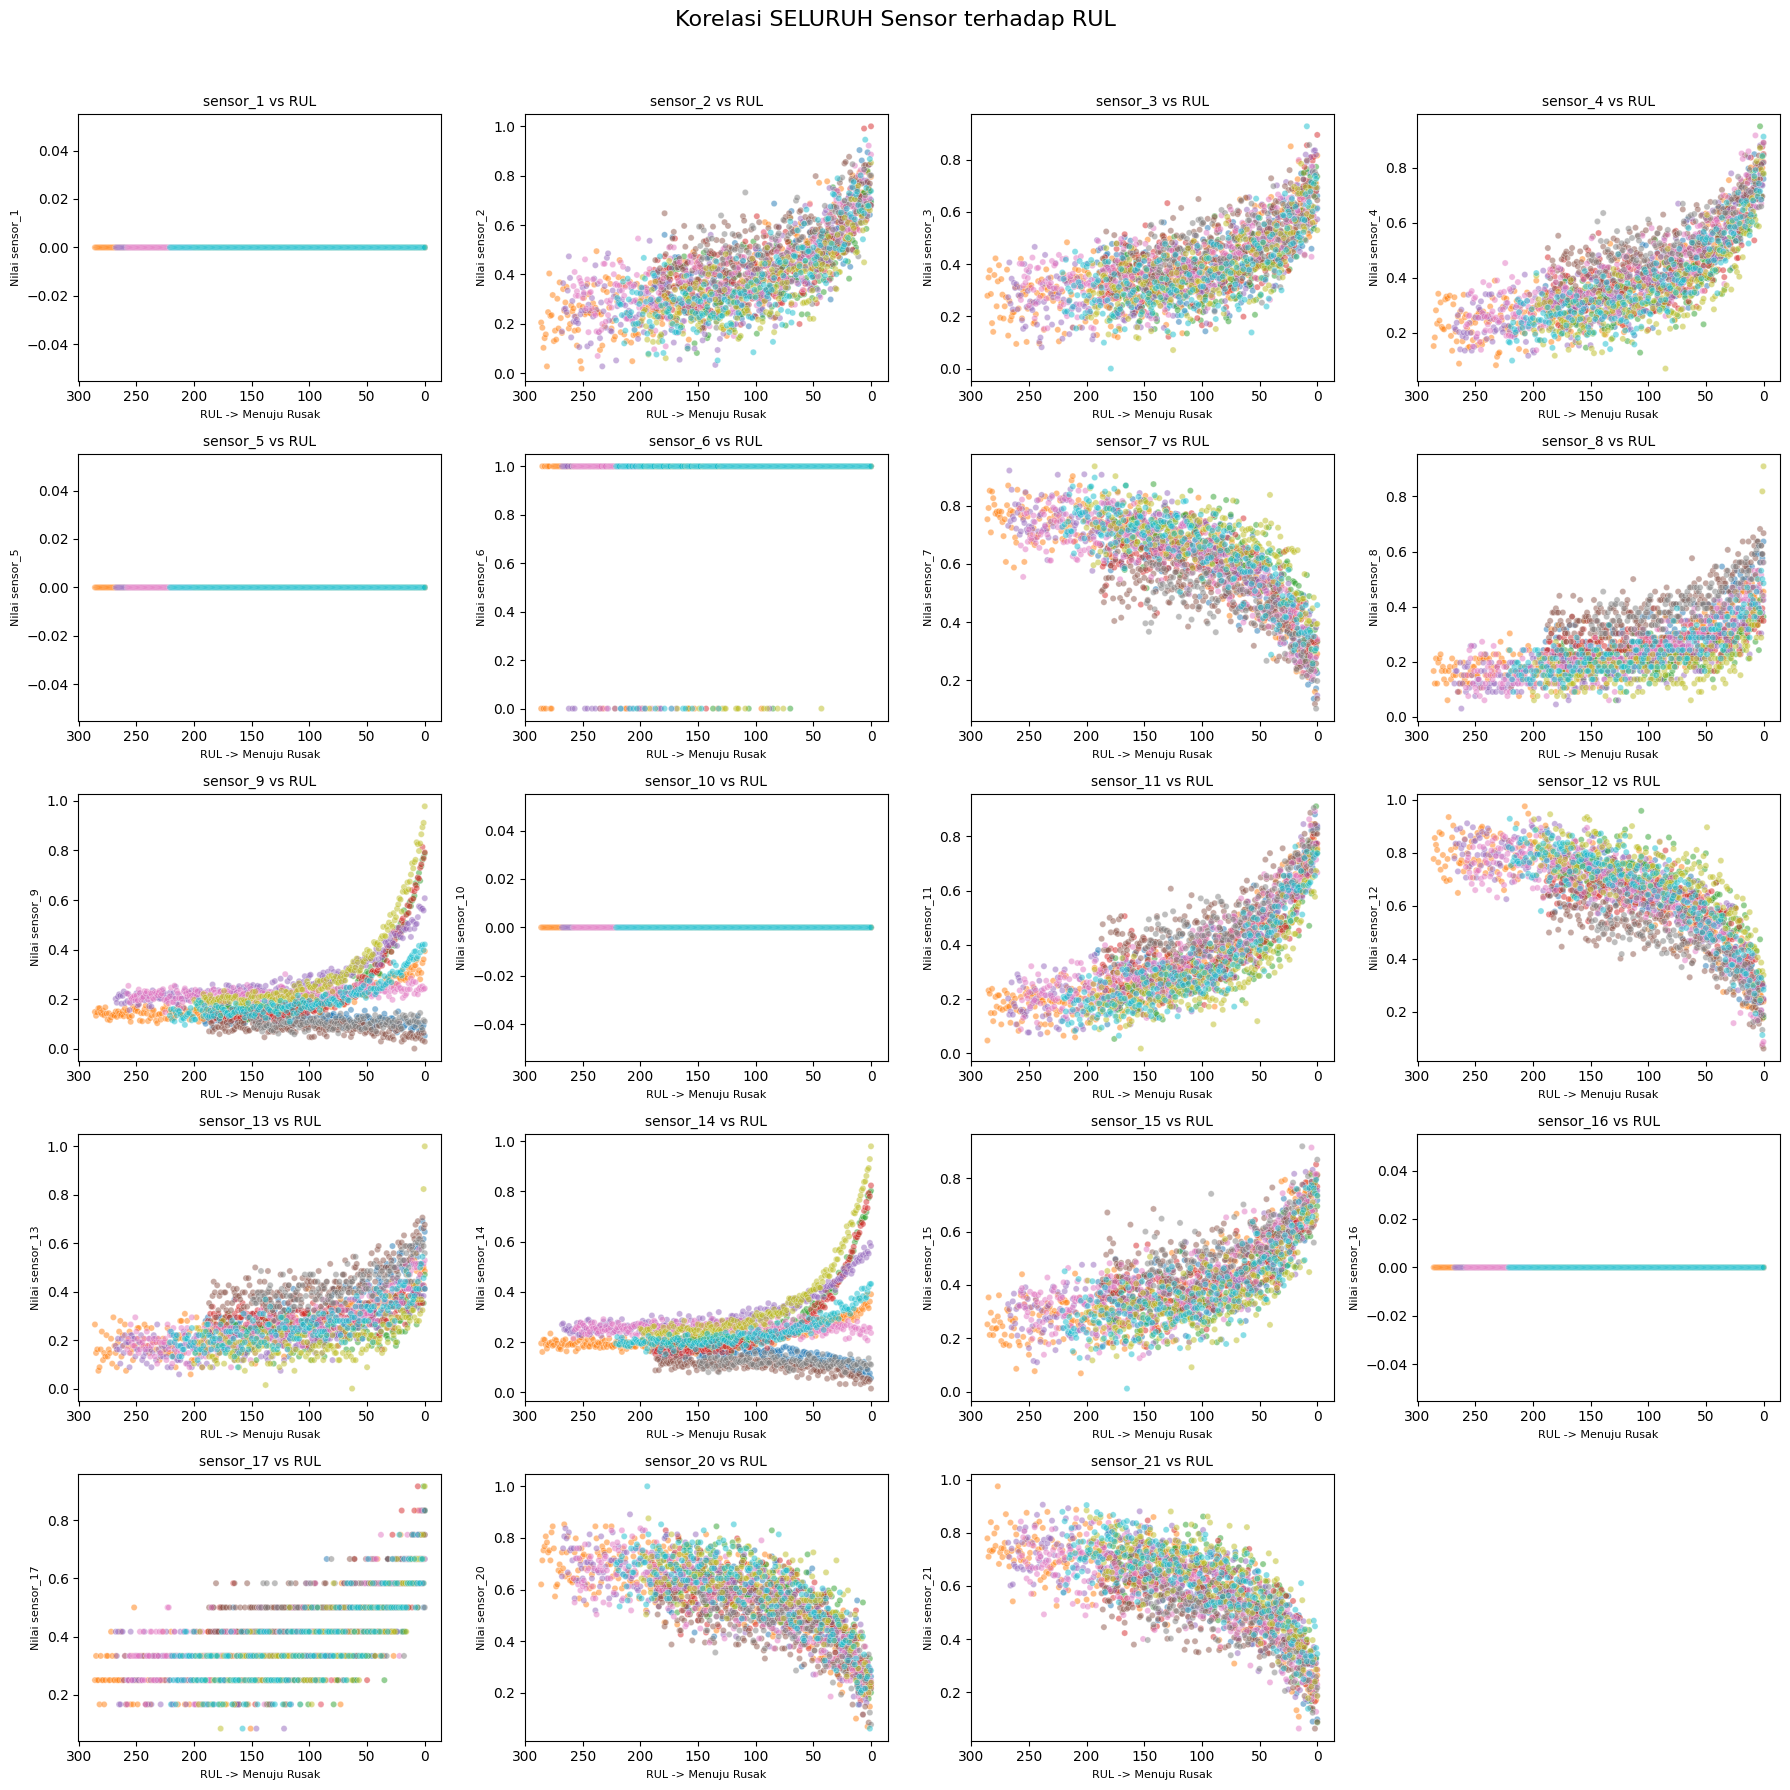

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# 1. Ambil semua nama kolom sensor yang ada di dataset (secara otomatis)
semua_sensor = [col for col in df_train.columns if col.startswith('sensor_')]

# 2. Hitung jumlah baris dan kolom kanvas secara otomatis
total_sensor = len(semua_sensor)
cols = 4  # Kita buat 4 kolom scatterplot per baris
rows = math.ceil(total_sensor / cols)

# 3. Siapkan kanvas dinamik
fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(18, rows * 3.5))
axes = axes.flatten()

# Ambil sampel 10 mesin pertama agar titik-titik tidak terlalu padat
df_sample = df_train[df_train['unit_id'] <= 10]

# 4. Looping untuk membuat scatterplot setiap sensor terhadap RUL
for i, sensor in enumerate(semua_sensor):
    sns.scatterplot(
        data=df_sample,
        x='RUL',
        y=sensor,
        hue='unit_id',
        palette='tab10',
        ax=axes[i],
        alpha=0.5,
        s=20,
        legend=False
    )
    axes[i].invert_xaxis() # Membalik sumbu X agar RUL besar di kiri (awal) dan RUL 0 di kanan (rusak)
    axes[i].set_title(f'{sensor} vs RUL', fontsize=10)
    axes[i].set_xlabel('RUL -> Menuju Rusak', fontsize=8)
    axes[i].set_ylabel(f'Nilai {sensor}', fontsize=8)

# Hapus subplot kosong jika jumlah sensor tidak pas membagi grid
for i in range(total_sensor, len(axes)):
    fig.delaxes(axes[i])

plt.suptitle('Korelasi SELURUH Sensor terhadap RUL', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

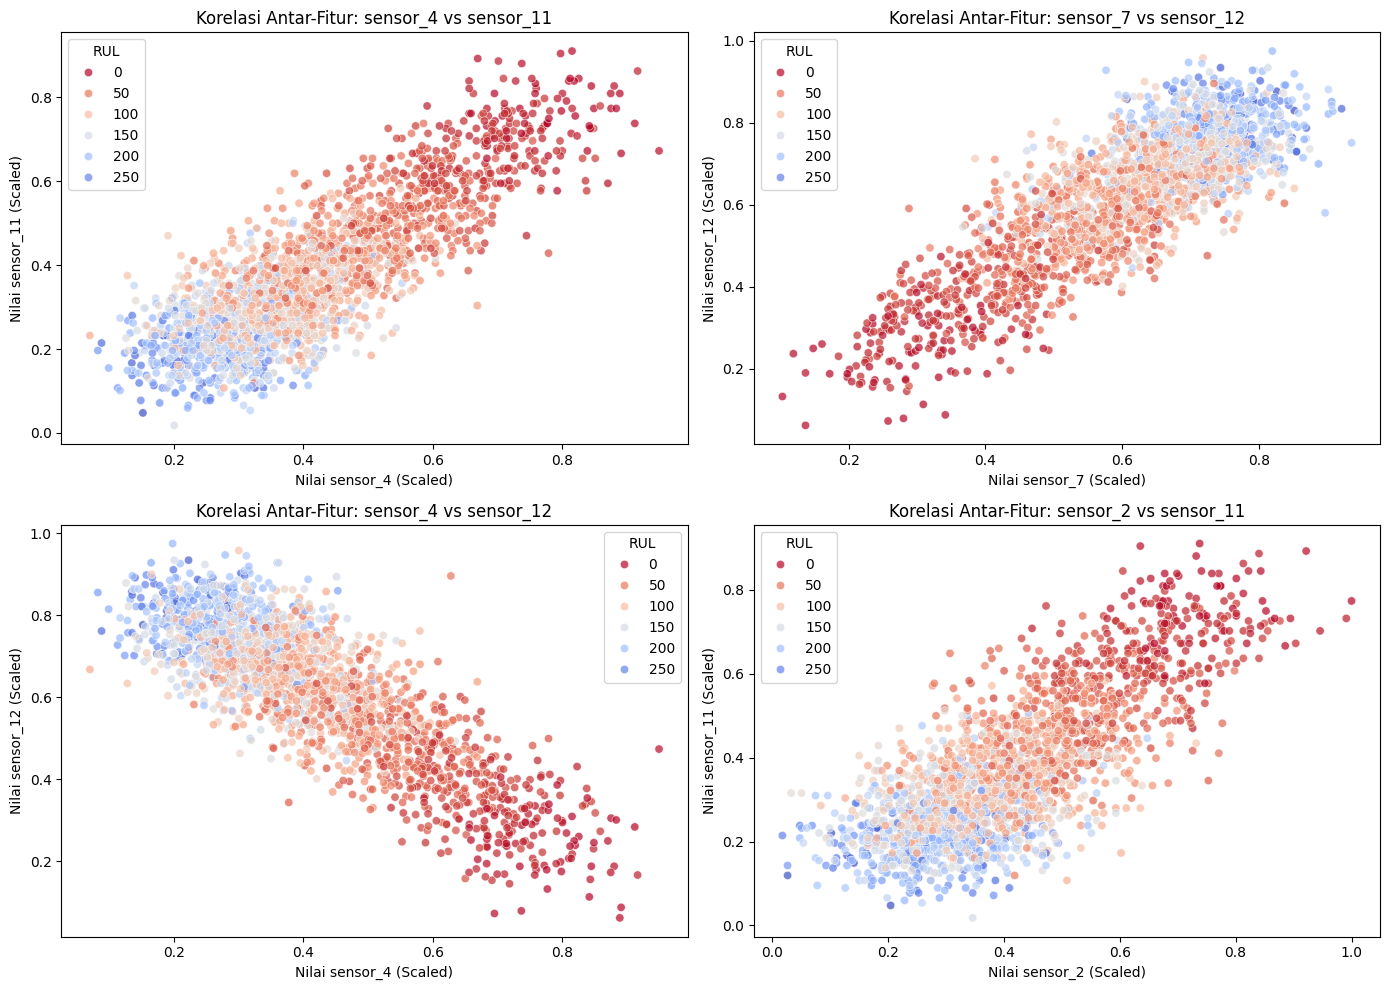

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pilih pasangan sensor yang ingin dibandingkan
pasangan_sensor = [
    ('sensor_4', 'sensor_11'),  # Pasangan dengan korelasi positif tinggi antar-sensor
    ('sensor_7', 'sensor_12'),  # Pasangan dengan korelasi positif tinggi antar-sensor
    ('sensor_4', 'sensor_12'),  # Pasangan dengan korelasi terbalik (positif vs negatif)
    ('sensor_2', 'sensor_11')   # Pasangan sensor tren naik lainnya
]

# 2. Siapkan kanvas 2x2
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

# Ambil sampel 10 mesin pertama agar titik tidak terlalu padat
df_sample = df_train[df_train['unit_id'] <= 10]

# 3. Looping untuk membuat scatterplot antar-sensor
for i, (sensor_x, sensor_y) in enumerate(pasangan_sensor):
    sns.scatterplot(
        data=df_sample,
        x=sensor_x,
        y=sensor_y,
        hue='RUL',
        palette='coolwarm_r', # Warna gradasi berdasarkan RUL (Biru=Sehat, Merah=Rusak)
        ax=axes[i],
        alpha=0.7
    )
    axes[i].set_title(f'Korelasi Antar-Fitur: {sensor_x} vs {sensor_y}')
    axes[i].set_xlabel(f'Nilai {sensor_x} (Scaled)')
    axes[i].set_ylabel(f'Nilai {sensor_y} (Scaled)')

plt.tight_layout()
plt.show()

Penjelasan Grafik
* Multikolinearitas Positif Sangat Tinggi (sensor_4 vs sensor_11, sensor_7 vs sensor_12, sensor_2 vs sensor_11):
  * Titik-titik membentuk garis diagonal miring ke atas yang sangat rapat. Ini menandakan bahwa kedua sensor dalam tiap pasangan memiliki hubungan linier searah yang sangat kuat.   
  * Ketika satu sensor nilainya naik, sensor pasangannya ikut naik secara konsisten. Titik-titik biru (mesin sehat/RUL tinggi) berkumpul di satu ujung dan bergerak serentak menjadi titik merah (mesin mendekati rusak/RUL 0) di ujung lainnya.   
* Multikolinearitas Negatif/Terbalik (sensor_4 vs sensor_12):
  * Titik-titik membentuk garis diagonal miring ke bawah. Ini membuktikan bahwa sensor_4 dan sensor_12 berlawanan arah secara linier sempurna: saat sensor_4 nilainya naik mendekati kondisi rusak, sensor_12 nilainya turun.   

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_sin

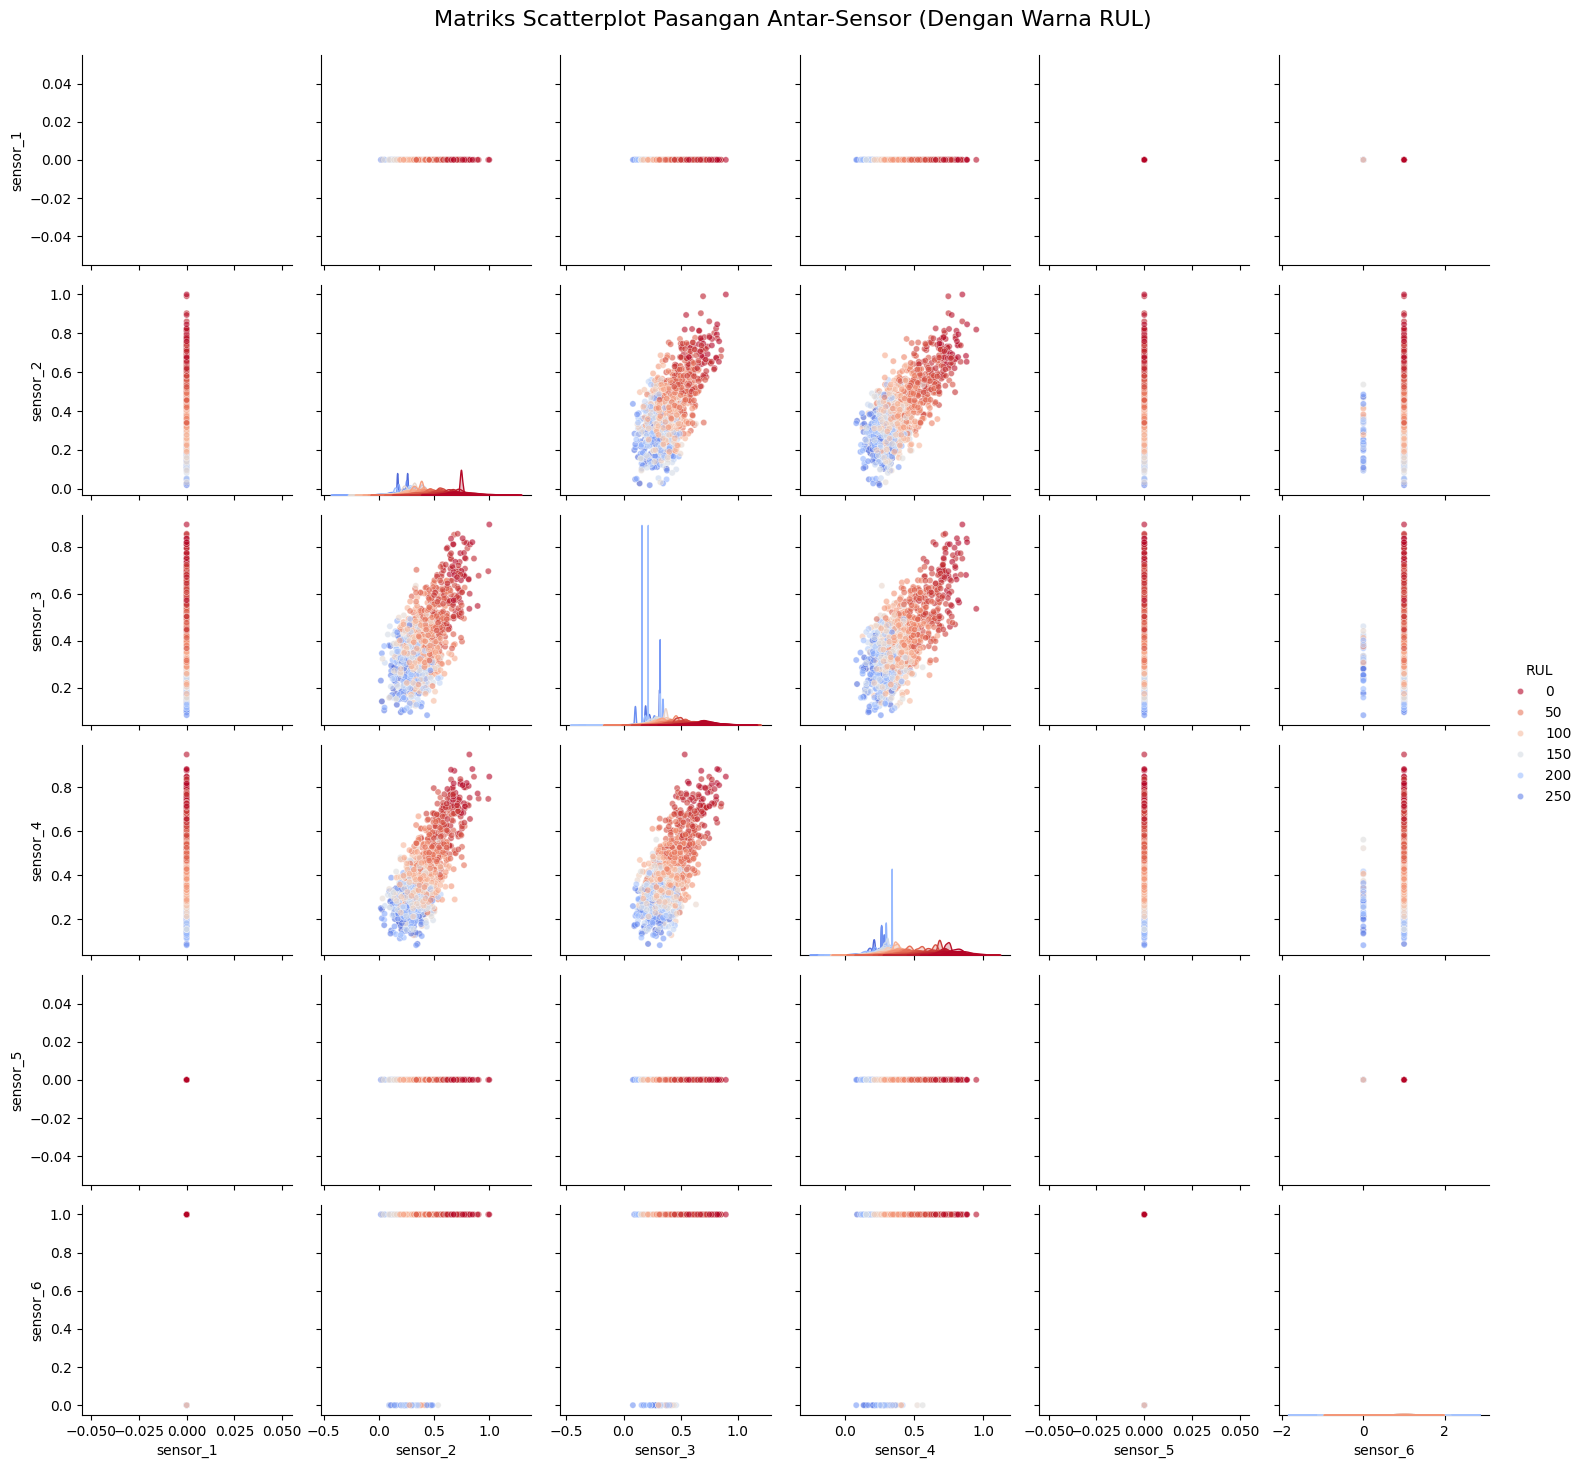

In [ ]:
# 1. Pilih daftar sensor yang paling aktif (bukan konstan)
sensor_aktif = [col for col in df_train.columns if col.startswith('sensor_')]

# 2. Gunakan PairGrid dari Seaborn untuk memetakan semua pasangan fitur
df_sample = df_train[df_train['unit_id'] <= 5] # Pakai 5 mesin agar rendering cepat

g = sns.PairGrid(df_sample, vars=sensor_aktif[:6], hue='RUL', palette='coolwarm_r') # Menampilkan 6 sensor utama lebih dulu
g.map_offdiag(sns.scatterplot, alpha=0.6, s=20)
g.map_diag(sns.kdeplot, fill=True)
g.add_legend(title='RUL')

plt.subplots_adjust(top=0.95)
g.fig.suptitle('Matriks Scatterplot Pasangan Antar-Sensor (Dengan Warna RUL)', fontsize=16)
plt.show()

/tmp/ipykernel_6873/1082101859.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_6873/1082101859.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_6873/1082101859.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_6873/1082101859.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_6873/1082101859.py:31: FutureWarning: 

P

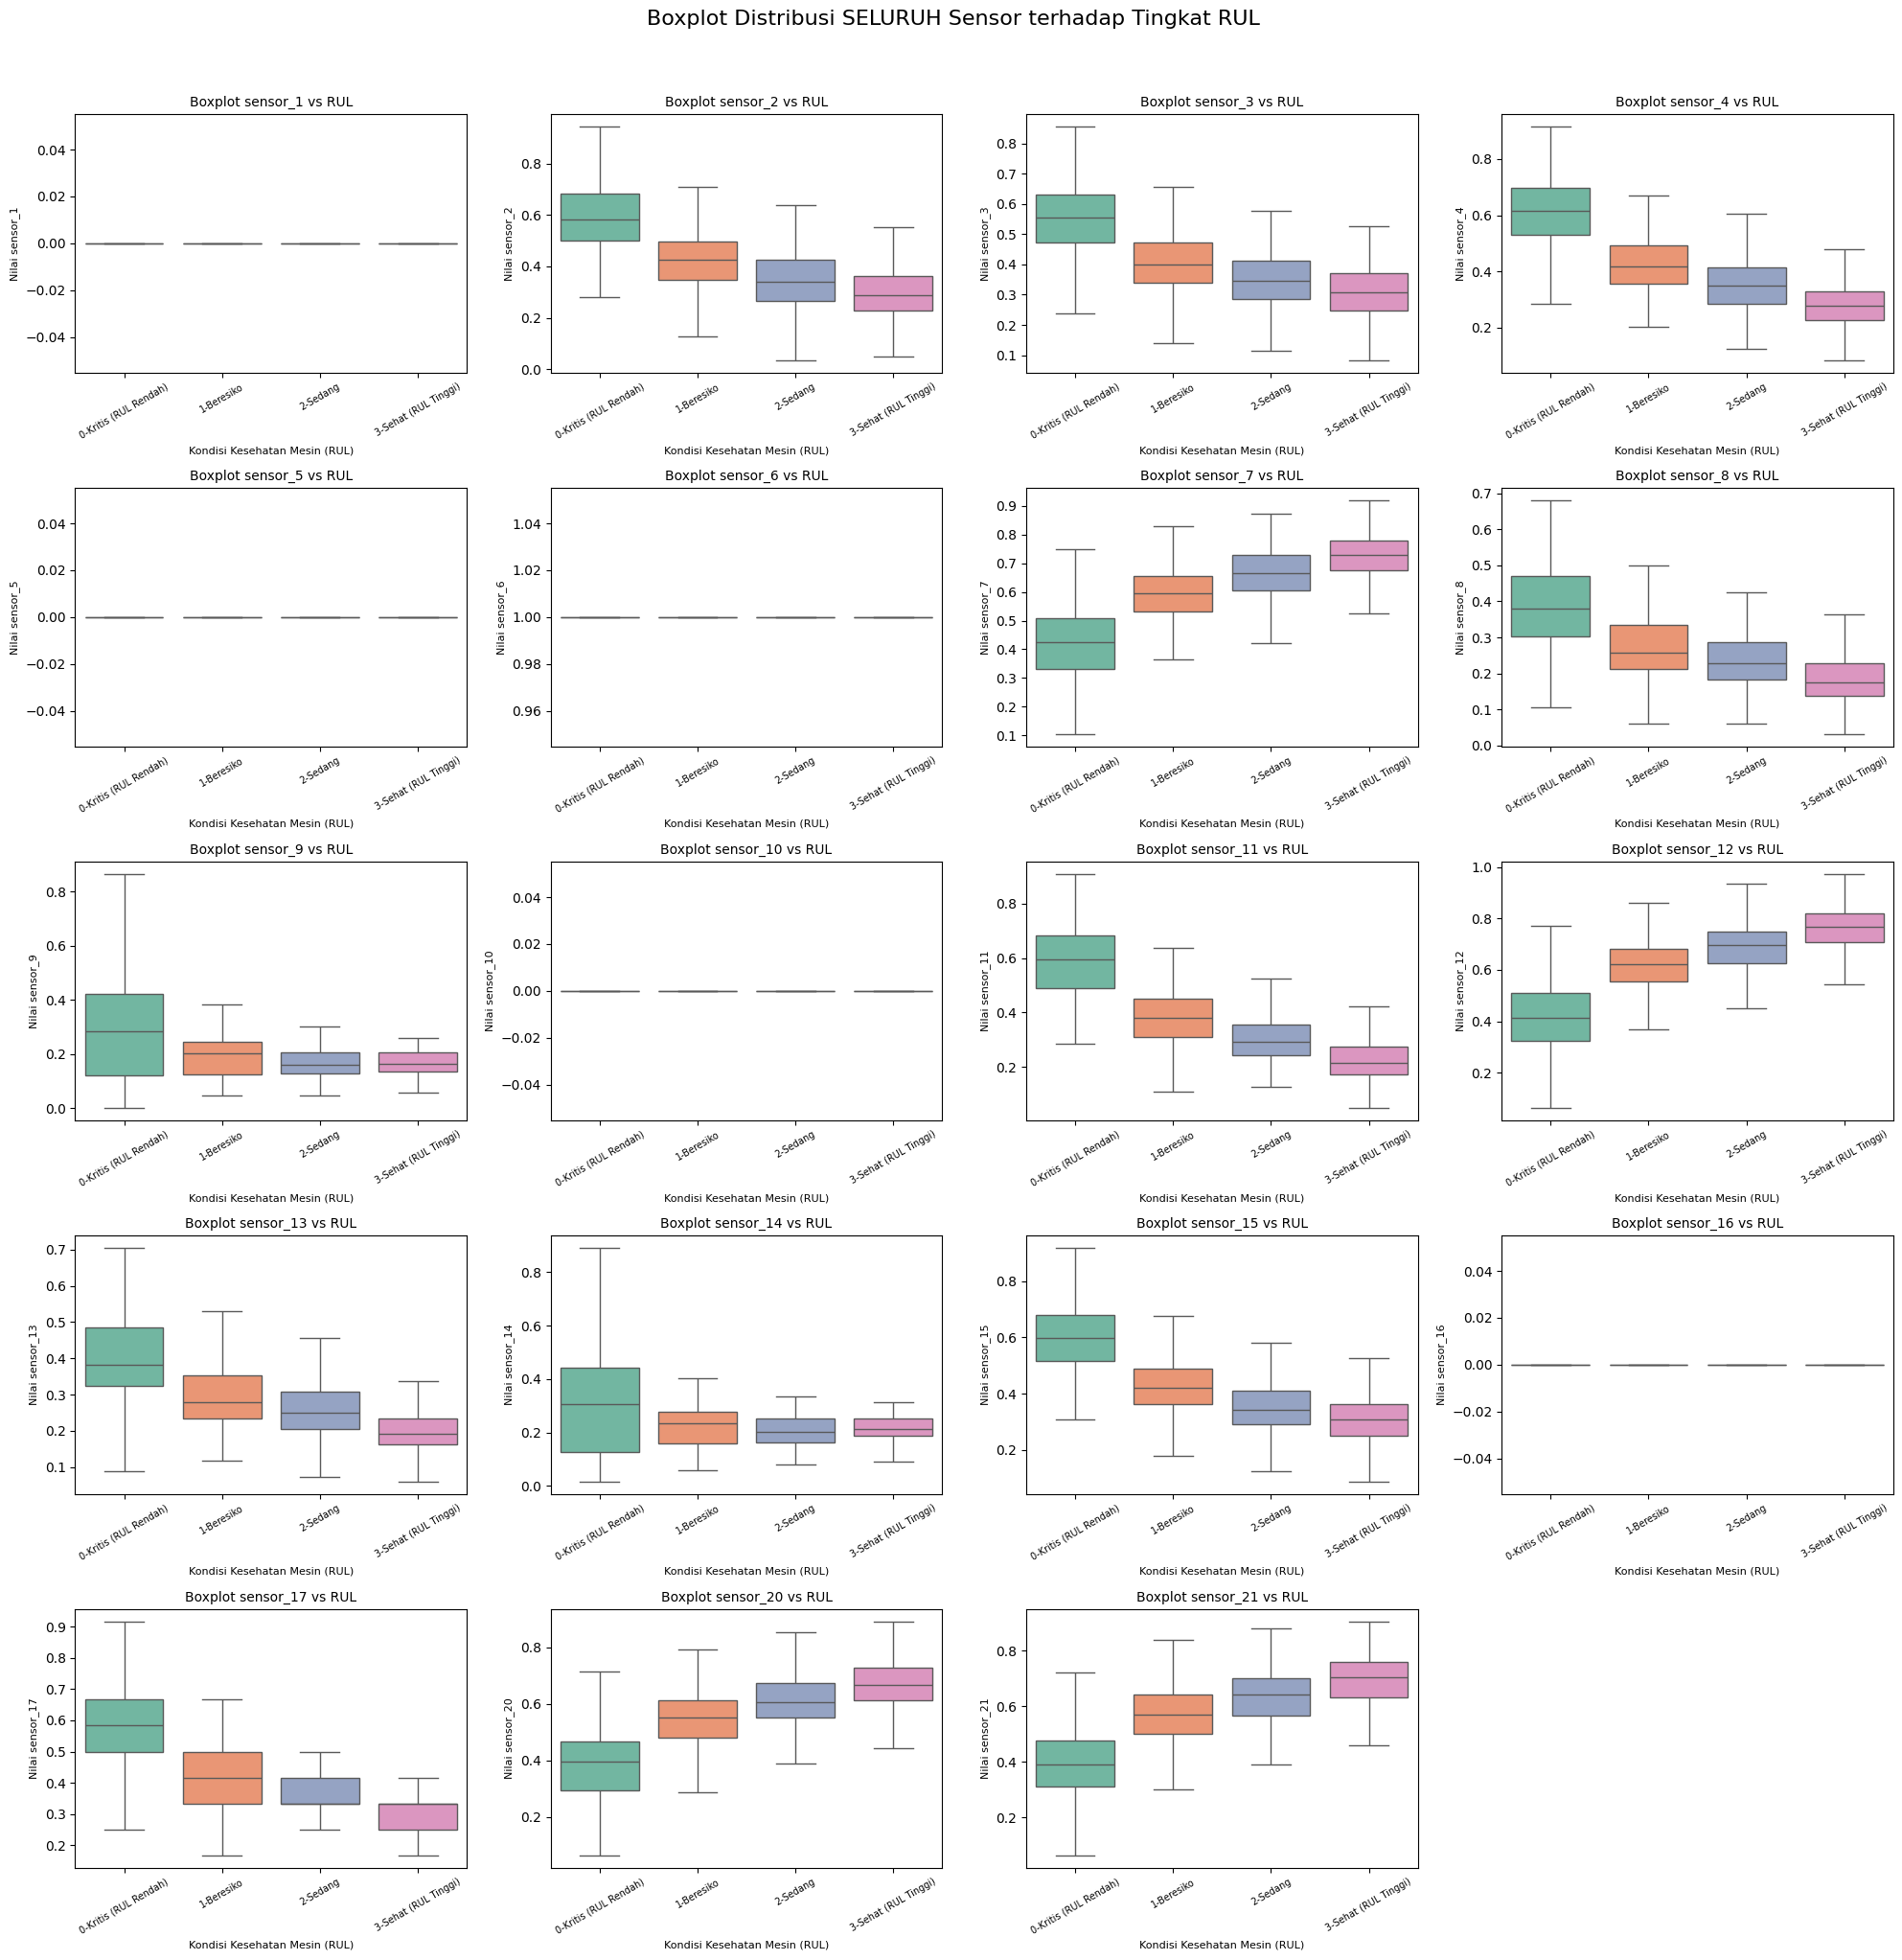

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import math

# 1. Ambil semua nama kolom sensor secara otomatis
semua_sensor = [col for col in df_train.columns if col.startswith('sensor_')]

# 2. Buat kategori RUL (Binning) untuk sumbu X Boxplot
# Mengelompokkan RUL menjadi 4 rentang kondisi kesehatan mesin
df_train['kategori_RUL'] = pd.qcut(
    df_train['RUL'],
    q=4,
    labels=['0-Kritis (RUL Rendah)', '1-Beresiko', '2-Sedang', '3-Sehat (RUL Tinggi)']
)

# 3. Hitung jumlah baris dan kolom kanvas secara otomatis
total_sensor = len(semua_sensor)
cols = 4  # 4 boxplot per baris
rows = math.ceil(total_sensor / cols)

# 4. Siapkan kanvas
fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(20, rows * 4))
axes = axes.flatten()

# Sample 10 mesin pertama agar proses rendering cepat dan rapi
df_sample = df_train[df_train['unit_id'] <= 10]

# 5. Looping Boxplot untuk SELURUH sensor terhadap kategori RUL
for i, sensor in enumerate(semua_sensor):
    sns.boxplot(
        data=df_sample,
        x='kategori_RUL',
        y=sensor,
        palette='Set2',
        ax=axes[i],
        showfliers=False # Menyembunyikan outlier ekstrem agar kotak terlihat jelas
    )
    axes[i].set_title(f'Boxplot {sensor} vs RUL', fontsize=10)
    axes[i].set_xlabel('Kondisi Kesehatan Mesin (RUL)', fontsize=8)
    axes[i].set_ylabel(f'Nilai {sensor}', fontsize=8)
    axes[i].tick_params(axis='x', rotation=30, labelsize=7)

# Hapus area subplot kosong jika ada
for i in range(total_sensor, len(axes)):
    fig.delaxes(axes[i])

plt.suptitle('Boxplot Distribusi SELURUH Sensor terhadap Tingkat RUL', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# Hapus kolom bantuan kategori_RUL setelah plotting agar dataframe tetap bersih
df_train = df_train.drop(columns=['kategori_RUL'])

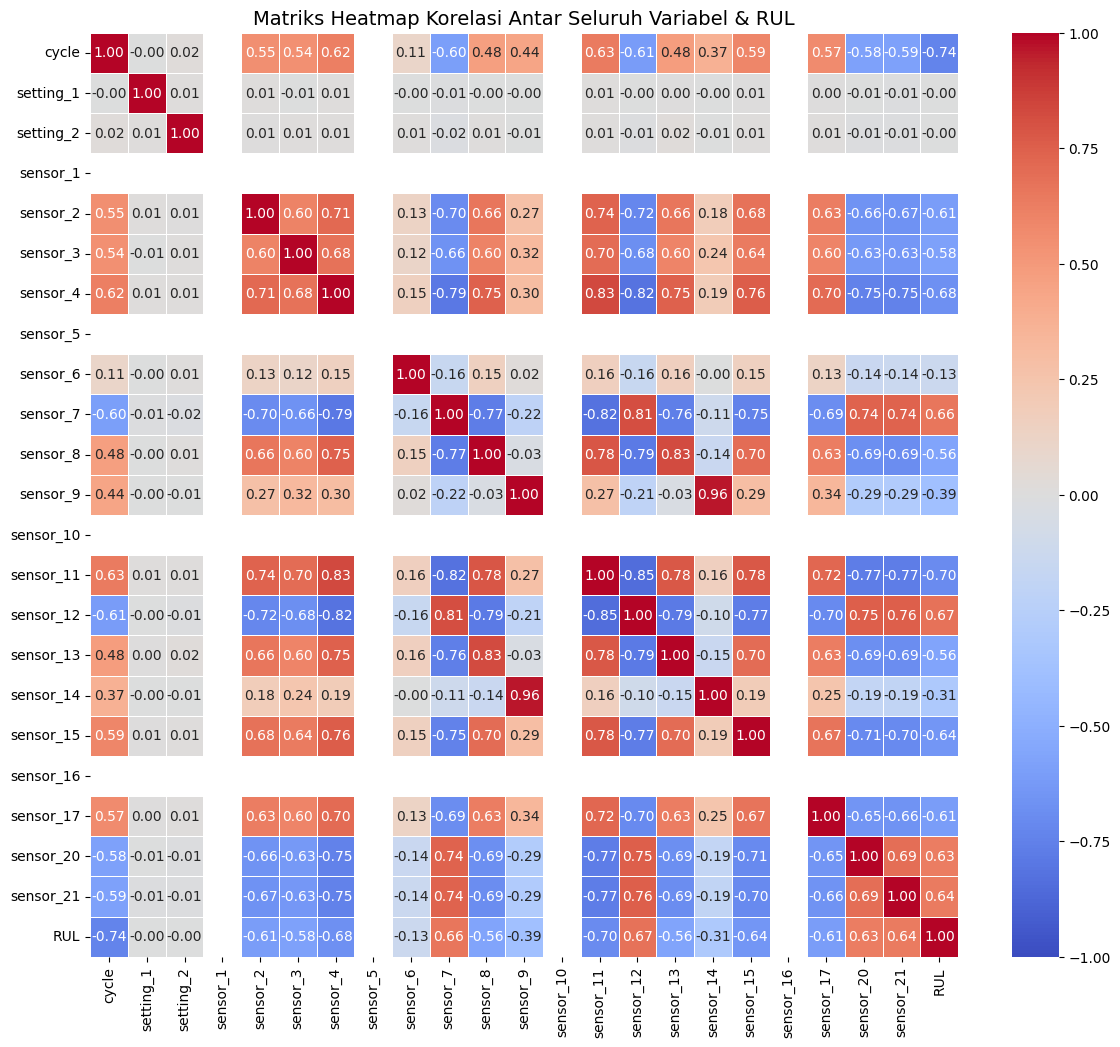

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 12))

# 1. Ambil kolom sensor, setting, dan RUL untuk dihitung korelasinya
kolom_evaluasi = [col for col in df_train.columns if col not in ['unit_id']]

# 2. Hitung matriks korelasi penuh (semua variabel terhadap semua variabel)
matriks_korelasi = df_train[kolom_evaluasi].corr()

# 3. Buat Heatmap Matriks Penuh
sns.heatmap(
    matriks_korelasi,
    annot=True,          # Menampilkan angka korelasi di dalam kotak
    fmt='.2f',           # Menampilkan 2 angka di belakang koma
    cmap='coolwarm',     # Warna Merah = Korelasi Positif, Biru = Korelasi Negatif
    vmin=-1, vmax=1,
    linewidths=0.5
)

plt.title('Matriks Heatmap Korelasi Antar Seluruh Variabel & RUL', fontsize=14)
plt.show()

#Rekomendasi
Adanya multikolinearitas yang sangat kuat antar-sensor ini memperbarui rekomendasi teknis yang perlu kamu sampaikan ke tim preprocessing dan modeling:
* Saran untuk Feature Selection (Redundansi Data):
  * Sensor-sensor ini merekam informasi yang pada dasarnya sama/redundan.
  * Jika tim modeling menggunakan algoritma linier (seperti Linear Regression, Ridge, atau Lasso), sangat disarankan untuk mengeliminasi salah satu sensor dari setiap pasangan yang berkorelasi linier kuat (misal: pilih salah satu antara sensor_4 atau sensor_11) agar model tidak mengalami gangguan kestabilan bobot akibat multikolinearitas.
* Saran untuk Algoritma Berbasis Pohon & Deep Learning:
  * Jika kelompokmu menggunakan Random Forest, XGBoost, atau LSTM (Neural Network), fitur-fitur redundan ini sebenarnya tidak akan merusak performa model secara signifikan.
  * Namun, membuang salah satu dari sensor yang redundan tetap direkomendasikan untuk memperingan beban komputasi dan mempercepat waktu training tanpa mengurangi akurasi prediksi.


#**Pengolahan Dataset 2-train_FD002.txt**